# DWD-Wetterdaten Berlin ab 2020

Dieses Notebook lädt ausschließlich tägliche DWD-Messwerte als CSV herunter. Es führt noch keine Wetteranalyse durch.

**Station:** Berlin-Dahlem (FU), DWD-ID `00403`, nahe Berlin-Zentrum. **Quelle:** DWD Climate Data Center, Tageswerte (KL). Der Download kombiniert die historische Datei bis 2025-12-31 mit der aktuellen Datei ab 2026 und reicht bis zum jüngsten dort verfügbaren Messdatum.

## Verfügbarkeit der Messgrößen

Die Stationsmetadaten weisen alle angeforderten Messgrößen bis zum **01.11.2026** aus: `TNK` (Tagesminimum, °C), `TXK` (Tagesmaximum, °C), `TMK` (Tagesmittel, °C), `RSK` (Niederschlagssumme, mm) und `SDK` (Sonnenscheindauer, Stunden).

Im Zeitraum 2020-01-01 bis 2026-11-01 liegen 2.483 Tagesdatensätze für 2.497 Kalendertage vor. Vom **04.03. bis 17.03.2025** fehlt ein kompletter Datensatz; außerdem gibt es vereinzelt fehlende Einzelwerte. Der Export ergänzt alle Kalendertage und schreibt fehlende Messwerte als leere CSV-Felder. Damit sind die Daten verfügbar, aber nicht lückenlos.

### Spalten und Quellen

| CSV-Spalte | DWD-Feld | Bedeutung | Einheit |
| --- | --- | --- | --- |
| `temp_min_c` | `TNK` | Tagesminimum in 2 m Höhe | °C |
| `temp_max_c` | `TXK` | Tagesmaximum in 2 m Höhe | °C |
| `temp_durchschnitt_c` | `TMK` | Tagesmitteltemperatur | °C |
| `niederschlag_mm` | `RSK` | tägliche Niederschlagssumme | mm |
| `sonnenstunden_h` | `SDK` | tägliche Sonnenscheindauer | h |

Historische Daten: [DWD-Archiv Berlin-Dahlem](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/). Aktuelle Daten: [DWD-Recent Berlin-Dahlem](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/recent/). Der DWD-Kennwert `-999` wird als fehlender Wert exportiert.

In [1]:
import csv
import io
import urllib.request
import zipfile
from datetime import date, datetime, timedelta
from pathlib import Path

## CSV herunterladen

Die folgende Zelle lädt die DWD-Historie und die aktuelle Tagesdatei, kombiniert sie ohne doppelte Tage und speichert eine CSV im aktuellen Notebook-Arbeitsverzeichnis. Für jeden Kalendertag ab 2020-01-01 gibt es eine Zeile; fehlende Messungen bleiben leer.

In [2]:
dwd_base_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/"
 )
historical_url = (
    dwd_base_url
    + "historical/tageswerte_KL_00403_19500101_20251231_hist.zip"
 )
recent_url = dwd_base_url + "recent/tageswerte_KL_00403_akt.zip"
start_date = date(2020, 1, 1)
today = date.today()

def read_dwd_product(url):
    with urllib.request.urlopen(url, timeout=60) as response:
        archive_bytes = response.read()

    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        product_name = next(
            name
            for name in archive.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        )
        product_text = archive.read(product_name).decode("latin-1")

    reader = csv.DictReader(io.StringIO(product_text), delimiter=";")
    return [
        {
            key.strip(): (value or "").strip()
            for key, value in row.items()
            if key
        }
        for row in reader
    ]

def get_measurement_date(row):
    value = row.get("MESS_DATUM", "")
    try:
        return datetime.strptime(value, "%Y%m%d").date()
    except ValueError:
        return None

historical_rows = read_dwd_product(historical_url)
recent_rows = read_dwd_product(recent_url)
historical_by_date = {}

for row in historical_rows:
    measurement_date = get_measurement_date(row)
    if measurement_date is not None and start_date <= measurement_date <= today:
        historical_by_date[measurement_date] = row

if not historical_by_date:
    raise ValueError("Die DWD-Historie enthält keine Daten ab 2020.")

historical_end = max(historical_by_date)
records_by_date = historical_by_date.copy()

for row in recent_rows:
    measurement_date = get_measurement_date(row)
    if (
        measurement_date is not None
        and historical_end < measurement_date <= today
    ):
        records_by_date[measurement_date] = row

latest_date = max(records_by_date)
if latest_date < start_date:
    raise ValueError("Die DWD-Dateien enthalten keine Daten ab 2020.")

column_map = {
    "temp_min_c": "TNK",
    "temp_max_c": "TXK",
    "temp_durchschnitt_c": "TMK",
    "niederschlag_mm": "RSK",
    "sonnenstunden_h": "SDK",
}
csv_columns = ["datum", *column_map.keys()]
csv_rows = []
missing_record_dates = []
current_date = start_date

while current_date <= latest_date:
    source_row = records_by_date.get(current_date)
    if source_row is None:
        missing_record_dates.append(current_date)

    output_row = {"datum": current_date.isoformat()}
    for output_column, dwd_column in column_map.items():
        value = source_row.get(dwd_column, "") if source_row else ""
        try:
            is_missing = not value or float(value) == -999
        except ValueError:
            is_missing = True
        output_row[output_column] = "" if is_missing else value

    csv_rows.append(output_row)
    current_date += timedelta(days=1)

csv_path = Path.cwd() / "dwd_berlin_dahlem_2020_bis_heute.csv"
with csv_path.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=csv_columns)
    writer.writeheader()
    writer.writerows(csv_rows)

print("Station: Berlin-Dahlem (FU), DWD-ID 00403")
print(f"Zeitraum: {start_date} bis {latest_date}")
print(f"Tageszeilen: {len(csv_rows)}; fehlende komplette Tage: {len(missing_record_dates)}")
if missing_record_dates:
    print(
        "Lückenzeitraum: "
        f"{min(missing_record_dates)} bis {max(missing_record_dates)}"
    )
for output_column in column_map:
    missing_count = sum(not row[output_column] for row in csv_rows)
    print(f"Fehlende Werte {output_column}: {missing_count}")
print(f"CSV gespeichert unter: {csv_path.resolve()}")

Station: Berlin-Dahlem (FU), DWD-ID 00403
Zeitraum: 2020-01-01 bis 2026-11-01
Tageszeilen: 2497; fehlende komplette Tage: 14
Lückenzeitraum: 2025-03-04 bis 2025-03-17
Fehlende Werte temp_min_c: 16
Fehlende Werte temp_max_c: 16
Fehlende Werte temp_durchschnitt_c: 16
Fehlende Werte niederschlag_mm: 15
Fehlende Werte sonnenstunden_h: 16
CSV gespeichert unter: /workspaces/seminar3/dwd_berlin_dahlem_2020_bis_heute.csv


## Durchschnittstemperatur im Jahresvergleich

Die Tagesmitteltemperatur wird für jedes Jahr als eigene farbige Linie über einen gemeinsamen Kalenderverlauf gelegt. Der 29. Februar bleibt bei Schaltjahren enthalten; fehlende DWD-Werte erscheinen als Lücken. Das jüngste Jahr ist unvollständig und reicht nur bis zum neuesten CSV-Datum.

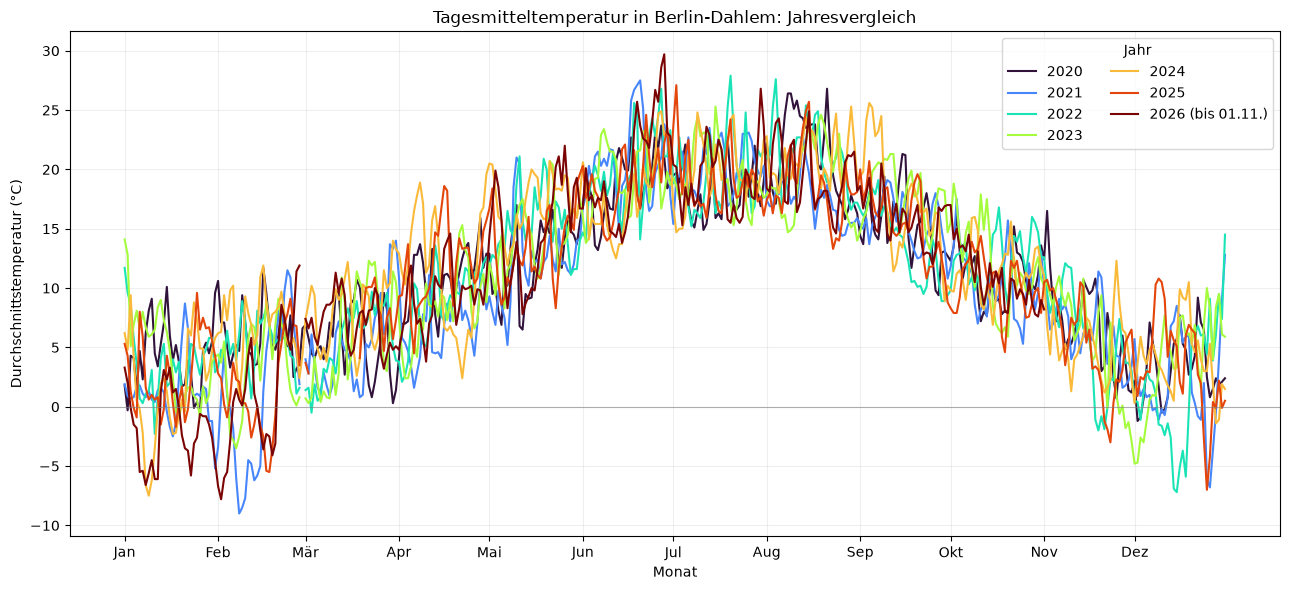

In [3]:
import csv
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

csv_path = Path.cwd() / "dwd_berlin_dahlem_2020_bis_heute.csv"
annual_temperatures = {}
latest_csv_date = None

with csv_path.open("r", newline="", encoding="utf-8") as csv_file:
    for row in csv.DictReader(csv_file):
        measurement_date = datetime.strptime(row["datum"], "%Y-%m-%d")
        latest_csv_date = measurement_date
        calendar_day = datetime(2000, measurement_date.month, measurement_date.day)
        temperature_value = row["temp_durchschnitt_c"].strip()
        annual_temperatures.setdefault(measurement_date.year, {})[calendar_day] = (
            float(temperature_value) if temperature_value else float("nan")
        )

if not annual_temperatures:
    raise ValueError(f"Keine Temperaturdaten in {csv_path.resolve()}")

years = sorted(annual_temperatures)
calendar_days = [datetime(2000, 1, 1) + timedelta(days=day) for day in range(366)]
color_positions = [index / max(1, len(years) - 1) for index in range(len(years))]
colors = plt.cm.turbo(color_positions)

fig, ax = plt.subplots(figsize=(13, 6))
for year, color in zip(years, colors):
    temperatures = [
        annual_temperatures[year].get(calendar_day, float("nan"))
        for calendar_day in calendar_days
    ]
    label = str(year)
    if year == latest_csv_date.year and latest_csv_date.month < 12:
        label = f"{year} (bis {latest_csv_date:%d.%m.})"
    ax.plot(calendar_days, temperatures, label=label, color=color, linewidth=1.5)

ax.set_title("Tagesmitteltemperatur in Berlin-Dahlem: Jahresvergleich")
ax.set_xlabel("Monat")
ax.set_ylabel("Durchschnittstemperatur (°C)")
ax.set_xticks([datetime(2000, month, 1) for month in range(1, 13)])
ax.set_xticklabels(
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
 )
ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
ax.grid(alpha=0.2)
ax.legend(title="Jahr", ncol=2)
fig.tight_layout()
plt.show()

Verglichene vollständige Jahre: [2020, 2021, 2022, 2023, 2024, 2025]
Mittlere tägliche Spannweite im Winter: 9.9 °C
Mittlere tägliche Spannweite im Sommer: 7.1 °C
Winter minus Sommer: +2.8 °C (+39 % gegenüber dem Sommer)


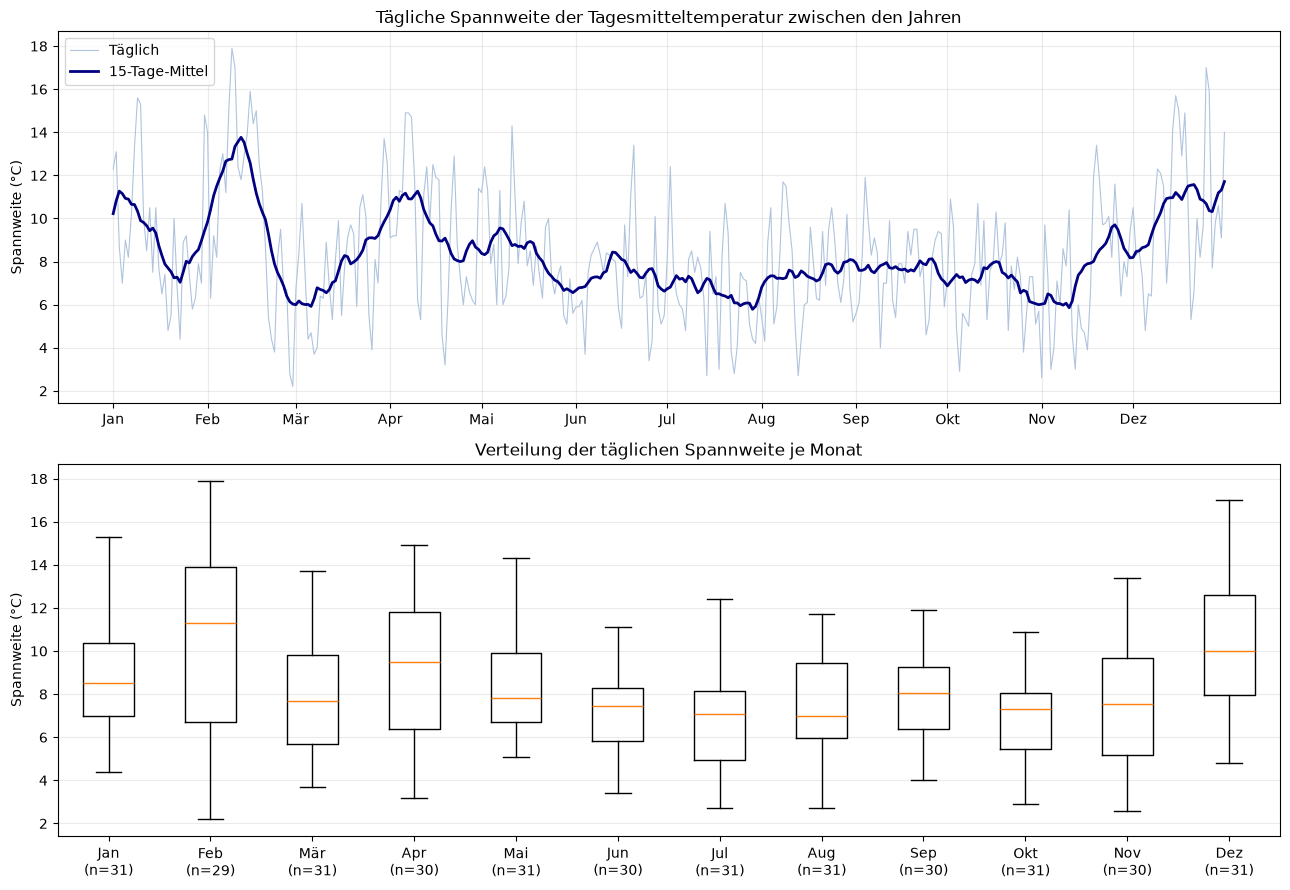

In [5]:
# Das jüngste Jahr ist unvollständig und wird für den fairen Vergleich ausgelassen.
complete_years = [year for year in years if year < latest_csv_date.year]
daily_ranges = []
monthly_ranges = {month: [] for month in range(1, 13)}

for index, calendar_day in enumerate(calendar_days):
    values = [
        annual_temperatures[year].get(calendar_day, float("nan"))
        for year in complete_years
    ]
    values = [value for value in values if value == value]  # NaN ausschließen

    if len(values) >= 2:
        spread = max(values) - min(values)
        daily_ranges.append((calendar_day, spread))
        monthly_ranges[calendar_day.month].append(spread)

winter_values = [
    spread
    for month in (12, 1, 2)
    for spread in monthly_ranges[month]
 ]
summer_values = [
    spread
    for month in (6, 7, 8)
    for spread in monthly_ranges[month]
 ]

winter_mean = sum(winter_values) / len(winter_values)
summer_mean = sum(summer_values) / len(summer_values)
difference = winter_mean - summer_mean
percent_difference = difference / summer_mean * 100 if summer_mean else float("nan")

print(f"Verglichene vollständige Jahre: {complete_years}")
print(f"Mittlere tägliche Spannweite im Winter: {winter_mean:.1f} °C")
print(f"Mittlere tägliche Spannweite im Sommer: {summer_mean:.1f} °C")
print(
    f"Winter minus Sommer: {difference:+.1f} °C "
    f"({percent_difference:+.0f} % gegenüber dem Sommer)"
 )

# 15-Tage-Mittel glättet die tägliche Spannweite für den Saisonverlauf.
smoothed_ranges = []
for index in range(len(daily_ranges)):
    window = daily_ranges[max(0, index - 7): index + 8]
    smoothed_ranges.append(
        sum(spread for _, spread in window) / len(window)
    )

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9))

dates = [day for day, _ in daily_ranges]
spreads = [spread for _, spread in daily_ranges]
ax1.plot(dates, spreads, color="lightsteelblue", linewidth=0.8, label="Täglich")
ax1.plot(
    dates,
    smoothed_ranges,
    color="navy",
    linewidth=2,
    label="15-Tage-Mittel",
 )
ax1.set_title("Tägliche Spannweite der Tagesmitteltemperatur zwischen den Jahren")
ax1.set_ylabel("Spannweite (°C)")
ax1.set_xticks([datetime(2000, month, 1) for month in range(1, 13)])
ax1.set_xticklabels(
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
 )
ax1.grid(alpha=0.25)
ax1.legend()

months = list(range(1, 13))
box_data = [monthly_ranges[month] for month in months]
month_labels = [
    f"{label}\n(n={len(monthly_ranges[month])})"
    for month, label in zip(
        months,
        ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
         "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"],
    )
 ]
ax2.boxplot(box_data, showfliers=False)
ax2.set_xticks(range(1, len(month_labels) + 1))
ax2.set_xticklabels(month_labels)
ax2.set_title("Verteilung der täglichen Spannweite je Monat")
ax2.set_ylabel("Spannweite (°C)")
ax2.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

## Interpretation der Temperaturspannweite

Die Diagramme vergleichen die **Tagesmitteltemperaturen der vollständigen Jahre 2020 bis 2025**. Für jeden Kalendertag wurde die höchste Tagesmitteltemperatur dieser Jahre minus die niedrigste berechnet. Die Spannweite zeigt also, wie unterschiedlich die Jahre an diesem Datum waren; sie ist keine Tagesschwankung zwischen Höchst- und Tiefsttemperatur.

### Saisonverlauf
Die dünne Linie zeigt die Spannweite für einzelne Tage, die dunkle Linie glättet kurzfristige Ausschläge über 15 Tage. Im Winter beträgt die mittlere Spannweite **9,9 °C**, im Sommer **7,1 °C**. Der Winterwert ist damit im Mittel **2,8 °C (rund 39 %) höher**. Die Unterschiede zwischen den Jahren waren in den betrachteten Wintertagen also größer als im Sommer. Besonders hohe Werte treten im Februar und Dezember auf; im Sommer ist die Spannweite meist kleiner.

### Monatsverteilung
Im unteren Boxplot ist jeder Monat nach der Verteilung seiner Tages-Spannweiten zusammengefasst. Die Linie in der Box markiert den Median, die Box umfasst die mittleren 50 % der Werte. Die Angaben `n=...` zeigen, wie viele Tage in den jeweiligen Monat eingeflossen sind. Die Verteilungen sind im Februar und Dezember breiter; im Sommer liegen die typischen Spannweiten niedriger. Ausreißer sind in diesem Boxplot ausgeblendet.

### Einordnung
Die Auswertung berücksichtigt sechs vollständige Jahre; das unvollständige Jahr 2026 ist ausgeschlossen. Sie beschreibt die Streuung **zwischen diesen Jahren**, aber weder einen langfristigen Erwärmungstrend noch die Schwankung innerhalb eines einzelnen Tages.

In [ ]:
# Typische Arbeitsschritte einer Datenanalyse

## 1. Problemdefinition und Zielsetzung
- Analysefrage und Geschäftsproblem klar formulieren
- Zielgröße, Kennzahlen und Erfolgsmaß definieren
- Umfang, Annahmen und Anforderungen festlegen

## 2. Datenbeschaffung und Datenintegration
- relevante Datenquellen identifizieren
- Daten importieren, zusammenführen und strukturieren
- Datumsangaben, Identifikatoren und Formate prüfen

## 3. Datenqualitätsprüfung
- Datentypen, fehlende Werte und Duplikate erkennen
- Konsistenz, Plausibilität und Vollständigkeit bewerten
- Ausreißer und inkonsistente Einträge analysieren

## 4. Explorative Datenanalyse (EDA)
- deskriptive Statistiken berechnen
- Verteilungen, Zentralwerte und Streuungen prüfen
- Korrelationen, Trends und Muster visualisieren
- Anomalien und relevante Segmentierungen identifizieren

## 5. Datenbereinigung und Feature Engineering
- fehlende Werte behandeln und imputieren
- inkonsistente Werte korrigieren
- Variablen transformieren, umbenennen und standardisieren
- neue Merkmale ableiten und aggregierte Kennzahlen erzeugen

## 6. Hypothesenbildung und Analysestrategie
- Hypothesen formulieren und prüfen
- relevante Variablen auswählen
- Vergleichsgrößen, Gruppen und Zeitfenster definieren

## 7. Modellierung und Validierung
- geeignete Methoden und Algorithmen auswählen
- Trainings- und Testdaten aufteilen
- Modelle trainieren, parameterisieren und evaluieren
- Qualitätsmetriken wie Accuracy, Precision, Recall, F1-Score oder RMSE vergleichen

## 8. Interpretation und Erkenntnisgewinn
- Ergebnisse im fachlichen Kontext bewerten
- Einflussfaktoren und Zusammenhänge interpretieren
- Modellgrenzen, Bias und statistische Unsicherheit berücksichtigen

## 9. Reporting und Dokumentation
- Ergebnisse, Kennzahlen und Visualisierungen zusammenfassen
- Handlungsempfehlungen und Schlussfolgerungen ableiten
- Analyseprozess nachvollziehbar dokumentieren

## 10. Präsentation und Umsetzung
- Ergebnisse verständlich kommunizieren
- Erkenntnisse mit Stakeholdern teilen
- Maßnahmen, Monitoring und nächste Schritte definieren

## 11. Iteration und Optimierung
- Feedback einholen und Analyse verbessern
- Modell oder Methodik weiterentwickeln
- Reproduzierbarkeit und langfristige Nutzung sichern

Diese Schritte bilden den typischen Ablauf einer datengetriebenen Analyse: von der Problemdefinition über die Datenaufbereitung, explorative Analyse, Modellierung, Interpretation bis hin zur verständlichen Präsentation der Ergebnisse.

# Datenprognose mit KI

## Ziel und Modellidee

Wir sagen jeweils die **Tagesmitteltemperatur des nächsten Tages** voraus. Für einen Zieltages `t` erhält das Modell sechs Eingaben: die Mitteltemperaturen der fünf vorhergehenden Tage (`t-5` bis `t-1`) und den Kalendertag im Jahr des Zieltages (`1` bis `365`). Der Zielwert ist die gemessene Mitteltemperatur am Tag `t`.

Als einfaches überwacht lernendes KI-Modell verwenden wir einen Random Forest Regressor. Die Bewertung erfolgt auf dem zeitlich letzten Teil der Daten, der beim Training nicht verwendet wird.

## Wahl des KI-Modells: Random Forest

Die Zielgröße ist eine **Zahl in °C**. Deshalb handelt es sich um ein Regressionsproblem, nicht um eine Klassifikation. Gewählt wird ein Random-Forest-Regressor aus scikit-learn.

- **Passend zur Datenmenge:** Die CSV liefert einige tausend gültige Trainingsfenster mit nur sechs Eingabemerkmalen. Dafür ist ein baumbasiertes Modell ein einfacher, gut nachvollziehbarer Startpunkt.
- **Kann nichtlineare Muster abbilden:** Die Temperatur der letzten Tage und die Jahreszeit können gemeinsam wirken; ein einzelner linearer Zusammenhang wäre dafür möglicherweise zu einfach.
- **Wenig Vorverarbeitung:** Entscheidungsbäume benötigen keine Skalierung der Temperatur- und Jahrestagswerte. Der Forest mittelt viele Bäume, was einzelne zufällige Entscheidungen abmildert.
- **Bewusste Begrenzung:** Ein Random Forest modelliert zeitliche Abläufe nicht von selbst und der numerische Jahrestag behandelt Jahresanfang und Jahresende nicht als Nachbarn. Hier ergänzen die fünf letzten Temperaturen die zeitliche Information; ein zyklisches Saisonmerkmal wäre eine mögliche spätere Verbesserung.

Das Modell ist für dieses Lernbeispiel ausgewählt, nicht als bestmögliches Wettermodell. Deshalb vergleichen wir es später auf zukünftigen, zurückgehaltenen Tagen mit der einfachen Vortags-Baseline.

### Schritt 1: Daten laden und prüfen

Wir verwenden die Tagesmitteltemperatur aus der zuvor heruntergeladenen DWD-CSV. Das Datum wird als Datumstyp eingelesen, die Temperatur numerisch konvertiert. Fehlende Werte bleiben fehlend und werden später nicht geschätzt; Trainingsbeispiele mit fehlenden oder nicht aufeinanderfolgenden Tagen werden ausgelassen.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

csv_path = Path.cwd() / "dwd_berlin_dahlem_2020_bis_heute.csv"
weather_df = pd.read_csv(csv_path, parse_dates=["datum"])
weather_df["temp_durchschnitt_c"] = pd.to_numeric(
    weather_df["temp_durchschnitt_c"],
    errors="coerce",
 )
weather_df = weather_df.sort_values("datum").reset_index(drop=True)

print(f"CSV-Datei: {csv_path.resolve()}")
print(f"Zeitraum: {weather_df['datum'].min().date()} bis {weather_df['datum'].max().date()}")
print(f"Tageszeilen: {len(weather_df)}")
print(
    "Fehlende Tagesmitteltemperaturen:",
    int(weather_df["temp_durchschnitt_c"].isna().sum()),
 )
display(weather_df[["datum", "temp_durchschnitt_c"]].head())

CSV-Datei: /workspaces/seminar3/dwd_berlin_dahlem_2020_bis_heute.csv
Zeitraum: 2020-01-01 bis 2026-11-01
Tageszeilen: 2497
Fehlende Tagesmitteltemperaturen: 16


,datum,temp_durchschnitt_c
0,2020-01-01,1.8
1,2020-01-02,-0.3
2,2020-01-03,4.3
3,2020-01-04,4.1
4,2020-01-05,1.4


### Schritt 2: Trainingsbeispiele erzeugen

Das Modell lernt aus vielen Beispielen der Form **Eingabe → Zielwert**. Für jeden Zieltag nehmen wir fünf vorhergehende Tagesmitteltemperaturen und den Jahrestag des Zieles. Wir verlangen sechs lückenlose Kalendertage; so wird etwa ein Fenster über eine fehlende DWD-Woche nicht fälschlich als aufeinanderfolgende Tage verwendet.

Da die Eingabe laut Vorgabe auf 1 bis 365 begrenzt ist, ordnen wir den 29. Februar dem Wert 59,5 zu und verschieben die Jahrestage danach in Schaltjahren um eins.

In [3]:
feature_columns = [
    "temp_vor_5_tagen_c",
    "temp_vor_4_tagen_c",
    "temp_vor_3_tagen_c",
    "temp_vor_2_tagen_c",
    "temp_vortag_c",
    "tag_im_jahr",
]

def tag_im_jahr_365(datum):
    if datum.is_leap_year:
        if datum.month == 2 and datum.day == 29:
            return 59.5
        if datum.month > 2:
            return float(datum.day_of_year - 1)
    return float(datum.day_of_year)

trainingszeilen = []
for ziel_index in range(5, len(weather_df)):
    fenster = weather_df.iloc[ziel_index - 5: ziel_index + 1]
    fenster_daten = pd.DatetimeIndex(fenster["datum"])
    erwartete_daten = pd.date_range(
        start=fenster_daten[0],
        periods=6,
        freq="D",
    )
    if not fenster_daten.equals(erwartete_daten):
        continue

    temperaturen = fenster["temp_durchschnitt_c"].to_numpy(dtype=float)
    if not np.isfinite(temperaturen).all():
        continue

    ziel_datum = fenster_daten[-1]
    trainingszeile = {
        name: float(value)
        for name, value in zip(feature_columns[:5], temperaturen[:5])
    }
    trainingszeile["tag_im_jahr"] = tag_im_jahr_365(ziel_datum)
    trainingszeile["ziel_datum"] = ziel_datum
    trainingszeile["zieltemperatur_c"] = float(temperaturen[-1])
    trainingszeilen.append(trainingszeile)

trainingsdaten = pd.DataFrame(trainingszeilen)
if trainingsdaten.empty:
    raise ValueError("Es wurden keine vollständigen Trainingsfenster gefunden.")

X = trainingsdaten[feature_columns]
y = trainingsdaten["zieltemperatur_c"]
print(f"Gültige Trainingsbeispiele: {len(trainingsdaten)}")
print(
    f"Zielzeitraum: {trainingsdaten['ziel_datum'].min().date()} bis "
    f"{trainingsdaten['ziel_datum'].max().date()}"
 )
display(trainingsdaten.head())

Gültige Trainingsbeispiele: 2471
Zielzeitraum: 2020-01-06 bis 2026-11-01


,temp_vor_5_tagen_c,temp_vor_4_tagen_c,temp_vor_3_tagen_c,temp_vor_2_tagen_c,temp_vortag_c,tag_im_jahr,ziel_datum,zieltemperatur_c
0,1.8,-0.3,4.3,4.1,1.4,6.0,2020-01-06,4.7
1,-0.3,4.3,4.1,1.4,4.7,7.0,2020-01-07,2.3
2,4.3,4.1,1.4,4.7,2.3,8.0,2020-01-08,6.2
3,4.1,1.4,4.7,2.3,6.2,9.0,2020-01-09,8.1
4,1.4,4.7,2.3,6.2,8.1,10.0,2020-01-10,9.1


### Schritt 3: Zeitlich getrennt trainieren und testen

Bei Zeitreihen darf nicht zufällig gemischt werden: Sonst könnte das Modell mit späteren Jahren trainieren und frühere Tage testen. Wir trainieren deshalb auf den ersten 80 % der zeitlich sortierten Beispiele und bewerten auf den letzten 20 %. Der Testzeitraum bleibt beim Modelltraining vollständig unberührt.

In [4]:
split_index = int(len(trainingsdaten) * 0.8)
if split_index == 0 or split_index == len(trainingsdaten):
    raise ValueError("Zu wenige Trainingsbeispiele für einen Train-/Test-Split.")

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
test_dates = trainingsdaten["ziel_datum"].iloc[split_index:]

print(f"Trainingsbeispiele: {len(X_train)}")
print(f"Testbeispiele: {len(X_test)}")
print(
    f"Trainingszeitraum: {trainingsdaten['ziel_datum'].iloc[0].date()} bis "
    f"{trainingsdaten['ziel_datum'].iloc[split_index - 1].date()}"
 )
print(
    f"Testzeitraum: {test_dates.iloc[0].date()} bis "
    f"{test_dates.iloc[-1].date()}"
 )

Trainingsbeispiele: 1976
Testbeispiele: 495
Trainingszeitraum: 2020-01-06 bis 2025-06-24
Testzeitraum: 2025-06-25 bis 2026-11-01


### Schritt 4: Random-Forest-Modell trainieren

Ein Random Forest bildet viele Entscheidungsbäume und mittelt deren Vorhersagen. Er kann nichtlineare Zusammenhänge zwischen den fünf jüngsten Temperaturen, dem Jahrestag und der Zieltemperatur erfassen. Für dieses Modell ist keine Skalierung der Eingabewerte erforderlich.

Wir trainieren ausschließlich auf dem ersten Zeitabschnitt. Zusätzlich verwenden wir als einfache Referenz die **Persistenz-Baseline**: Sie sagt für morgen dieselbe Temperatur wie am Vortag voraus.

In [6]:
modell = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
 )
modell.fit(X_train, y_train)
vorhersage_test = modell.predict(X_test)
vorhersage_baseline = X_test["temp_vortag_c"].to_numpy()

metriken = pd.DataFrame(
    {
        "MAE (°C)": [
            mean_absolute_error(y_test, vorhersage_test),
            mean_absolute_error(y_test, vorhersage_baseline),
        ],
        "RMSE (°C)": [
            np.sqrt(mean_squared_error(y_test, vorhersage_test)),
            np.sqrt(mean_squared_error(y_test, vorhersage_baseline)),
        ],
        "R²": [
            r2_score(y_test, vorhersage_test),
            r2_score(y_test, vorhersage_baseline),
        ],
    },
    index=["Random Forest", "Vortags-Baseline"],
 )

display(metriken.round(3))
test_ergebnisse = pd.DataFrame(
    {
        "datum": test_dates.to_numpy(),
        "ist_c": y_test.to_numpy(),
        "prognose_c": vorhersage_test,
        "baseline_c": vorhersage_baseline,
    }
 )
test_anzeige = test_ergebnisse.head(10).copy()
test_anzeige[["ist_c", "prognose_c", "baseline_c"]] = test_anzeige[
    ["ist_c", "prognose_c", "baseline_c"]
 ].round(2)
display(test_anzeige)

,MAE (°C),RMSE (°C),R²
Random Forest,1.661,2.115,0.923
Vortags-Baseline,1.693,2.181,0.919


,datum,ist_c,prognose_c,baseline_c
0,2025-06-25,20.1,18.75,18.5
1,2025-06-26,21.8,22.31,20.1
2,2025-06-27,18.9,21.30,21.8
3,2025-06-28,22.2,18.97,18.9
4,2025-06-29,23.5,21.46,22.2
5,2025-06-30,19.6,21.34,23.5
6,2025-07-01,23.6,18.59,19.6
7,2025-07-02,27.1,21.61,23.6
8,2025-07-03,21.2,23.06,27.1
9,2025-07-04,17.9,19.57,21.2


### Schritt 5: Genauigkeit auf unbekannten Tagen bewerten

Bei einer Temperaturprognose ist „Accuracy“ keine passende Prozentkennzahl. **MAE** ist der durchschnittliche absolute Fehler in °C; **RMSE** bestraft größere Fehler stärker; **R²** beschreibt, wie viel der Teststreuung das Modell erklärt (1 ist ideal, 0 entspricht ungefähr dem Mittelwert-Basismodell).

Beim aktuellen Datensatz erreicht der Random Forest **MAE 1,661 °C**, gegenüber **1,693 °C** für die Vortags-Baseline. Das ist nur eine kleine Verbesserung von rund 1,9 % beim MAE. Der hohe R²-Wert allein bedeutet daher nicht, dass die Vorhersage nahezu fehlerfrei ist.

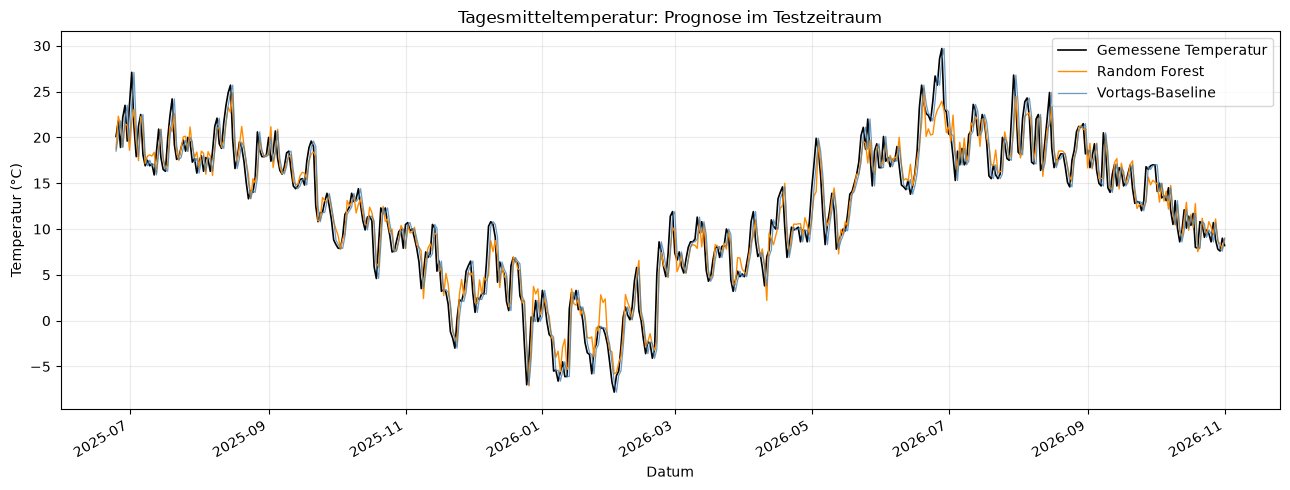

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    test_dates,
    y_test.to_numpy(),
    color="black",
    linewidth=1.2,
    label="Gemessene Temperatur",
 )
ax.plot(
    test_dates,
    vorhersage_test,
    color="darkorange",
    linewidth=1,
    label="Random Forest",
 )
ax.plot(
    test_dates,
    vorhersage_baseline,
    color="steelblue",
    linewidth=0.9,
    alpha=0.8,
    label="Vortags-Baseline",
 )
ax.set_title("Tagesmitteltemperatur: Prognose im Testzeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Vergleichsmodell: neuronales Netzwerk

Das neuronale Netz erhält für jeden der letzten fünf Tage **Tagesminimum, Tagesmaximum, Tagesmittel, Niederschlagsmenge und Sonnenstunden**. Das sind 25 Wettermerkmale; der Jahrestag des Prognosetages kommt als sechstes Merkmal hinzu. Ziel bleibt die Tagesmitteltemperatur des Folgetages.

Wir verwenden ein kleines mehrschichtiges Perzeptron (MLP). Ein `StandardScaler` ist Teil einer Pipeline und wird nur auf Trainingsdaten angepasst. Zur Vergleichbarkeit nutzen wir denselben zeitlichen Stichtag wie beim Random Forest und werten alle Modelle auf den gemeinsamen Testtagen aus.

In [9]:
neural_weather_columns = [
    "temp_min_c",
    "temp_max_c",
    "temp_durchschnitt_c",
    "sonnenstunden_h",
    "niederschlag_mm",
]
nn_weather_df = weather_df.copy()
for column in neural_weather_columns:
    nn_weather_df[column] = pd.to_numeric(nn_weather_df[column], errors="coerce")

nn_feature_columns = [
    f"{column}_vor_{lag}_tagen"
    for lag in range(5, 0, -1)
    for column in neural_weather_columns
 ] + ["tag_im_jahr"]

nn_rows = []
for target_index in range(5, len(nn_weather_df)):
    input_window = nn_weather_df.iloc[target_index - 5: target_index]
    target_row = nn_weather_df.iloc[target_index]
    target_date = target_row["datum"]
    observed_dates = pd.DatetimeIndex(input_window["datum"].tolist() + [target_date])
    expected_dates = pd.date_range(end=target_date, periods=6, freq="D")
    if not observed_dates.equals(expected_dates):
        continue

    input_values = input_window[neural_weather_columns].to_numpy(dtype=float)
    target_value = target_row["temp_durchschnitt_c"]
    if not np.isfinite(input_values).all() or not np.isfinite(target_value):
        continue

    sample = {}
    for lag in range(5, 0, -1):
        past_row = input_window.iloc[5 - lag]
        for column in neural_weather_columns:
            sample[f"{column}_vor_{lag}_tagen"] = float(past_row[column])
    sample["tag_im_jahr"] = tag_im_jahr_365(target_date)
    sample["ziel_datum"] = target_date
    sample["zieltemperatur_c"] = float(target_value)
    nn_rows.append(sample)

nn_trainingsdaten = pd.DataFrame(nn_rows)
if nn_trainingsdaten.empty:
    raise ValueError("Es wurden keine vollständigen NN-Trainingsfenster gefunden.")

test_start_date = test_dates.iloc[0]
nn_trainingsdaten = nn_trainingsdaten.sort_values("ziel_datum").reset_index(drop=True)
nn_train = nn_trainingsdaten[nn_trainingsdaten["ziel_datum"] < test_start_date]
nn_test = nn_trainingsdaten[nn_trainingsdaten["ziel_datum"] >= test_start_date]
if nn_train.empty or nn_test.empty:
    raise ValueError("Der gemeinsame zeitliche Train-/Testzeitraum ist leer.")

X_nn_train = nn_train[nn_feature_columns]
y_nn_train = nn_train["zieltemperatur_c"]
X_nn_test = nn_test[nn_feature_columns]
y_nn_test = nn_test["zieltemperatur_c"]

print(f"Wettermerkmale pro Beispiel: {len(nn_feature_columns)}")
print(f"NN-Trainingsbeispiele: {len(nn_train)}")
print(f"NN-Testbeispiele vor Abgleich: {len(nn_test)}")
print(f"Gemeinsamer Teststart: {test_start_date.date()}")
display(nn_trainingsdaten.head())

Wettermerkmale pro Beispiel: 26
NN-Trainingsbeispiele: 1976
NN-Testbeispiele vor Abgleich: 495
Gemeinsamer Teststart: 2025-06-25


,temp_min_c_vor_5_tagen,temp_max_c_vor_5_tagen,temp_durchschnitt_c_vor_5_tagen,sonnenstunden_h_vor_5_tagen,niederschlag_mm_vor_5_tagen,temp_min_c_vor_4_tagen,temp_max_c_vor_4_tagen,temp_durchschnitt_c_vor_4_tagen,sonnenstunden_h_vor_4_tagen,niederschlag_mm_vor_4_tagen,...,sonnenstunden_h_vor_2_tagen,niederschlag_mm_vor_2_tagen,temp_min_c_vor_1_tagen,temp_max_c_vor_1_tagen,temp_durchschnitt_c_vor_1_tagen,sonnenstunden_h_vor_1_tagen,niederschlag_mm_vor_1_tagen,tag_im_jahr,ziel_datum,zieltemperatur_c
0,-2.8,5.0,1.8,2.9,0.0,-4.1,6.2,-0.3,7.5,0.0,...,0.0,3.0,-1.4,3.6,1.4,2.1,0.0,6.0,2020-01-06,4.7
1,-4.1,6.2,-0.3,7.5,0.0,0.8,6.9,4.3,0.0,4.4,...,2.1,0.0,1.9,7.3,4.7,2.1,0.0,7.0,2020-01-07,2.3
2,0.8,6.9,4.3,0.0,4.4,1.7,5.6,4.1,0.0,3.0,...,2.1,0.0,-2.1,5.3,2.3,0.0,0.2,8.0,2020-01-08,6.2
3,1.7,5.6,4.1,0.0,3.0,-1.4,3.6,1.4,2.1,0.0,...,0.0,0.2,3.1,8.2,6.2,0.0,1.9,9.0,2020-01-09,8.1
4,-1.4,3.6,1.4,2.1,0.0,1.9,7.3,4.7,2.1,0.0,...,0.0,1.9,7.0,9.7,8.1,0.0,5.3,10.0,2020-01-10,9.1


### Schritt 4: Neuronales Netz trainieren

Ein MLP besteht aus Eingabe-, versteckten und Ausgabeschichten. Die Eingabeschicht erhält die 26 Merkmale, die Ausgabeschicht liefert eine Temperatur. `StandardScaler` bringt die unterschiedlich skalierten Eingaben auf vergleichbare Größenordnungen; da er in der Pipeline liegt, wird er ausschließlich mit dem Trainingszeitraum angepasst.

Das MLP wird mit derselben zeitlichen Grenze wie der Random Forest trainiert. Für den Leistungsvergleich werden anschließend nur Testtage verwendet, an denen beide Modelle und die Baseline eine Prognose haben.

In [11]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

neuronales_netz = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=42,
    ),
 )
neuronales_netz.fit(X_nn_train, y_nn_train)
nn_vorhersage_test = neuronales_netz.predict(X_nn_test)

nn_test_ergebnisse = pd.DataFrame(
    {
        "datum": nn_test["ziel_datum"].to_numpy(),
        "nn_prognose_c": nn_vorhersage_test,
    }
 )
gemeinsame_testwerte = test_ergebnisse.merge(
    nn_test_ergebnisse,
    on="datum",
    how="inner",
    validate="one_to_one",
 ).sort_values("datum")
if gemeinsame_testwerte.empty:
    raise ValueError("Die Modelle haben keine gemeinsamen Testtage.")

ist_temperatur = gemeinsame_testwerte["ist_c"]
modellvergleiche = []
for modell_name, spalte in [
    ("Random Forest", "prognose_c"),
    ("Neuronales Netz", "nn_prognose_c"),
    ("Vortags-Baseline", "baseline_c"),
]:
    prognose = gemeinsame_testwerte[spalte]
    modellvergleiche.append(
        {
            "Modell": modell_name,
            "MAE (°C)": mean_absolute_error(ist_temperatur, prognose),
            "RMSE (°C)": np.sqrt(mean_squared_error(ist_temperatur, prognose)),
            "R²": r2_score(ist_temperatur, prognose),
        }
    )

vergleich_neuronales_netz = pd.DataFrame(modellvergleiche).set_index("Modell")
print(f"Gemeinsame Testtage für alle Modelle: {len(gemeinsame_testwerte)}")
print(
    f"Gemeinsamer Testzeitraum: {gemeinsame_testwerte['datum'].min().date()} bis "
    f"{gemeinsame_testwerte['datum'].max().date()}"
 )
display(vergleich_neuronales_netz.round(3))

Gemeinsame Testtage für alle Modelle: 495
Gemeinsamer Testzeitraum: 2025-06-25 bis 2026-11-01


,MAE (°C),RMSE (°C),R²
Modell,,,
Random Forest,1.661,2.115,0.923
Neuronales Netz,1.798,2.280,0.911
Vortags-Baseline,1.693,2.181,0.919


### Schritt 5: Modelle fair vergleichen

Alle drei Ansätze werden anhand derselben 495 Testtage vom 25.06.2025 bis 01.11.2026 verglichen. Das neuronale Netz hat hier einen MAE von **1,798 °C** und einen RMSE von **2,280 °C**. Damit ist es in diesem Test etwas ungenauer als der Random Forest (MAE 1,661 °C) und auch als die einfache Vortags-Baseline (MAE 1,693 °C). Mehr Eingabemerkmale und ein neuronales Netz führen bei dieser Datenmenge also nicht automatisch zu einer besseren Prognose.

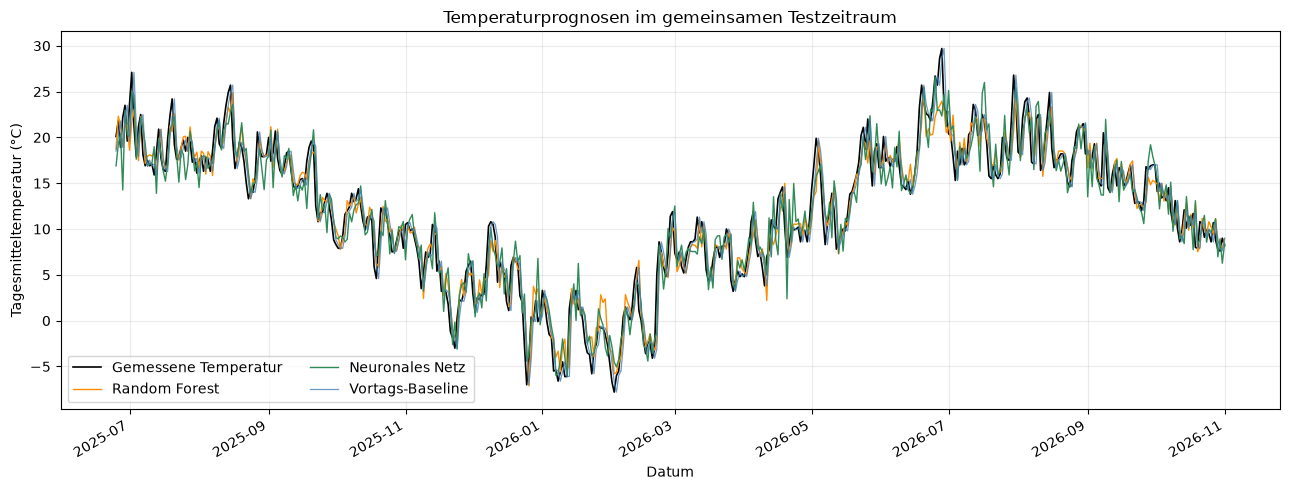

In [12]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    gemeinsame_testwerte["datum"],
    gemeinsame_testwerte["ist_c"],
    color="black",
    linewidth=1.2,
    label="Gemessene Temperatur",
 )
ax.plot(
    gemeinsame_testwerte["datum"],
    gemeinsame_testwerte["prognose_c"],
    color="darkorange",
    linewidth=1,
    label="Random Forest",
 )
ax.plot(
    gemeinsame_testwerte["datum"],
    gemeinsame_testwerte["nn_prognose_c"],
    color="seagreen",
    linewidth=1,
    label="Neuronales Netz",
 )
ax.plot(
    gemeinsame_testwerte["datum"],
    gemeinsame_testwerte["baseline_c"],
    color="steelblue",
    linewidth=0.9,
    alpha=0.8,
    label="Vortags-Baseline",
 )
ax.set_title("Temperaturprognosen im gemeinsamen Testzeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### Schritt 6: Prognose für den nächsten verfügbaren Tag

Die Testmetriken oben stammen weiterhin vom unangetasteten Testzeitraum. Für eine echte nächste Prognose trainieren wir dieselbe Modellkonfiguration anschließend neu mit **allen** verfügbaren Beispielen. Als Eingabe dienen die letzten fünf zusammenhängenden DWD-Tagesmittel und der Jahrestag des Folgetages.

In [8]:
letzte_fuenf = weather_df.tail(5)
letzte_fuenf_daten = pd.DatetimeIndex(letzte_fuenf["datum"])
erwartete_letzte_daten = pd.date_range(
    end=letzte_fuenf_daten[-1],
    periods=5,
    freq="D",
 )
letzte_temperaturen = letzte_fuenf["temp_durchschnitt_c"].to_numpy(dtype=float)

if not letzte_fuenf_daten.equals(erwartete_letzte_daten):
    raise ValueError("Die letzten fünf CSV-Zeilen sind keine aufeinanderfolgenden Tage.")
if not np.isfinite(letzte_temperaturen).all():
    raise ValueError("Für die letzten fünf Tage fehlen Temperaturmesswerte.")

naechster_tag = letzte_fuenf_daten[-1] + pd.Timedelta(days=1)
naechste_eingabe = {
    name: float(value)
    for name, value in zip(feature_columns[:5], letzte_temperaturen)
}
naechste_eingabe["tag_im_jahr"] = tag_im_jahr_365(naechster_tag)
naechste_eingabe_df = pd.DataFrame([naechste_eingabe], columns=feature_columns)

endmodell = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
 )
endmodell.fit(X, y)
prognose_naechster_tag = endmodell.predict(naechste_eingabe_df)[0]
baseline_naechster_tag = letzte_temperaturen[-1]

print(f"Letzter verfügbarer Messwert: {letzte_fuenf_daten[-1].date()}")
print(f"Prognosedatum: {naechster_tag.date()}")
print(f"Prognostizierte Tagesmitteltemperatur: {prognose_naechster_tag:.1f} °C")
print(f"Vortags-Baseline zum Vergleich: {baseline_naechster_tag:.1f} °C")

Letzter verfügbarer Messwert: 2026-11-01
Prognosedatum: 2026-11-02
Prognostizierte Tagesmitteltemperatur: 8.9 °C
Vortags-Baseline zum Vergleich: 8.2 °C


### Prognose des neuronalen Netzes für den nächsten Tag

Für die aktuelle NN-Prognose werden dieselben fünf letzten Tage verwendet, nun aber mit allen fünf Messgrößen pro Tag. Das finale Netz wird dafür mit allen verfügbaren vollständigen Trainingsfenstern neu trainiert.

In [13]:
letzte_fuenf_nn = nn_weather_df.tail(5)
letzte_fuenf_nn_daten = pd.DatetimeIndex(letzte_fuenf_nn["datum"])
erwartete_nn_daten = pd.date_range(
    end=letzte_fuenf_nn_daten[-1],
    periods=5,
    freq="D",
 )
letzte_nn_werte = letzte_fuenf_nn[neural_weather_columns].to_numpy(dtype=float)

if not letzte_fuenf_nn_daten.equals(erwartete_nn_daten):
    raise ValueError("Die letzten fünf Tage sind nicht lückenlos vorhanden.")
if not np.isfinite(letzte_nn_werte).all():
    raise ValueError(
        "Mindestens eine der fünf Wettergrößen fehlt in den letzten fünf Tagen; "
        "die NN-Prognose kann so nicht erstellt werden."
    )

nn_naechster_tag = letzte_fuenf_nn_daten[-1] + pd.Timedelta(days=1)
nn_naechste_eingabe = {}
for lag in range(5, 0, -1):
    past_row = letzte_fuenf_nn.iloc[5 - lag]
    for column in neural_weather_columns:
        nn_naechste_eingabe[f"{column}_vor_{lag}_tagen"] = float(past_row[column])
nn_naechste_eingabe["tag_im_jahr"] = tag_im_jahr_365(nn_naechster_tag)
nn_naechste_eingabe_df = pd.DataFrame(
    [nn_naechste_eingabe],
    columns=nn_feature_columns,
 )

nn_finales_netz = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=42,
    ),
 )
nn_finales_netz.fit(
    nn_trainingsdaten[nn_feature_columns],
    nn_trainingsdaten["zieltemperatur_c"],
 )
nn_prognose_naechster_tag = nn_finales_netz.predict(nn_naechste_eingabe_df)[0]

print(f"Letzter verfügbarer Messtag: {letzte_fuenf_nn_daten[-1].date()}")
print(f"NN-Prognosedatum: {nn_naechster_tag.date()}")
print(f"NN-Tagesmitteltemperatur: {nn_prognose_naechster_tag:.1f} °C")
print(f"Vortags-Baseline: {letzte_nn_werte[-1, 2]:.1f} °C")

Letzter verfügbarer Messtag: 2026-11-01
NN-Prognosedatum: 2026-11-02
NN-Tagesmitteltemperatur: 8.1 °C
Vortags-Baseline: 8.2 °C


### Grenzen der Prognose

Beide Modelle sind einfache Ein-Tages-Schätzungen und keine meteorologischen Vorhersagen. Der Random Forest verwendet die fünf letzten Tagesmitteltemperaturen und den Jahrestag; das neuronale Netz nutzt zusätzlich Minimum, Maximum, Niederschlag und Sonnenstunden der fünf letzten Tage. Keines der Modelle kennt zukünftige Wetterfronten, Wind- oder Wolkenprognosen.

Im gemeinsamen Testzeitraum war das neuronale Netz etwas ungenauer als Random Forest und Vortags-Baseline. Die Daten stammen nur von einer Station und umfassen wenige Jahre; das MLP wurde nicht umfassend optimiert. Die ausgegebene Prognose ist daher ein Lern- und Vergleichsbeispiel, keine verlässliche Entscheidungsgrundlage.